# Sree Ram Roshan A S - 24BAD113

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist

In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)


In [4]:
plt.figure(figsize=(10, 4))

<Figure size 1000x400 with 0 Axes>

<Figure size 1000x400 with 0 Axes>

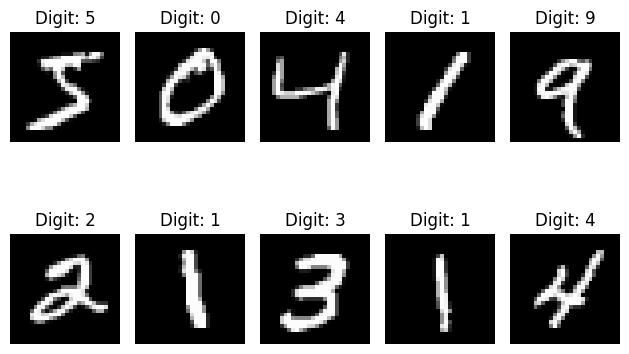

In [5]:
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title("Digit: {}".format(y_train[i]))
    plt.axis('off')

plt.tight_layout()
plt.show()

In [6]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

In [7]:
print("After flattening:")
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

After flattening:
Training data: (60000, 784)
Testing data: (10000, 784)


# Part B

In [8]:
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model

In [9]:
input_img = Input(shape=(784,))

encoded = Dense(128, activation='relu')(input_img)
latent = Dense(32, activation='relu', name='latent_space')(encoded)

decoded = Dense(128, activation='relu')(latent)
output_img = Dense(784, activation='sigmoid')(decoded)

In [10]:
autoencoder = Model(input_img, output_img)

encoder = Model(input_img, latent)

decoder_input = Input(shape=(32,))
decoder_layer = autoencoder.layers[-2](decoder_input)
decoder_output = autoencoder.layers[-1](decoder_layer)

decoder = Model(decoder_input, decoder_output)

In [11]:
print("ENCODER SUMMARY")
encoder.summary()

print("DECODER SUMMARY")
decoder.summary()

print("AUTOENCODER SUMMARY")
autoencoder.summary()

ENCODER SUMMARY


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_space (Dense)            │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,608 (408.62 KB)

 Trainable params: 104,608 (408.62 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_space (Dense)            │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

# Part C

In [12]:
autoencoder.compile(
    optimizer='adam',
    loss='binary_crossentropy'
)

history = autoencoder.fit(
    x_train,
    x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)

print("Final Training Loss:",
      history.history['loss'][-1])

print("Final Validation Loss:",
      history.history['val_loss'][-1])

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - loss: 0.2259 - val_loss: 0.1532
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1360 - val_loss: 0.1210
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1162 - val_loss: 0.1094
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1078 - val_loss: 0.1033
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1025 - val_loss: 0.0992
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0994 - val_loss: 0.0970
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0975 - val_loss: 0.0953
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0958 - val_loss: 0.0940
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0945 - val_loss: 0.0928
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0934 - val_loss: 0.0918
Final Training Loss: 0.09343135356903076
Final Validation Loss: 0.09184375405311584


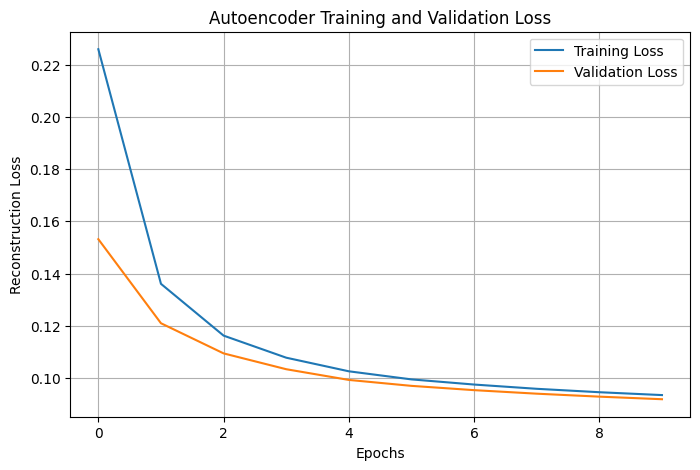

In [13]:
# Plot loss curves
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'],
         label='Training Loss')

plt.plot(history.history['val_loss'],
         label='Validation Loss')

plt.title('Autoencoder Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Reconstruction Loss')

plt.legend()
plt.grid(True)
plt.show()

# Part D

In [14]:
encoded_images = encoder.predict(x_test)

print("Original Input Dimension:", x_test.shape[1])
print("Latent Dimension:", encoded_images.shape[1])

print("Encoded Data Shape:", encoded_images.shape)

reconstructed_images = decoder.predict(encoded_images)

print("Reconstructed Data Shape:",reconstructed_images.shape)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Original Input Dimension: 784
Latent Dimension: 32
Encoded Data Shape: (10000, 32)
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Reconstructed Data Shape: (10000, 784)
